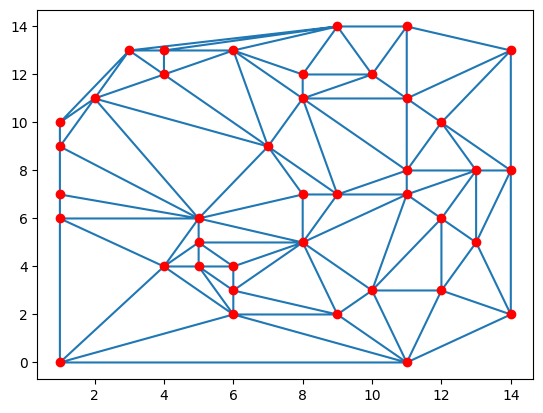

In [212]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import Delaunay
import random

npoints = 40
np.random.seed(111) #to reproduce meshes remove for production
points = np.random.randint(0,15, size=(npoints, 2))
points = np.unique(points, axis=0)

"""
Dirty way to ensure that there are npoints unique
points in the mesh
"""
max_iter = 100
itera = 0
while points.shape[0]-npoints<0:
    next_points = np.random.randint(0,10, size=(npoints-points.shape[0], 2))
    points = np.append(points, next_points, axis=0)
    points = np.unique(points, axis=0)
    # print(next_points.shape[0], points.shape[0])
    itera += 1
    if itera>max_iter:
        break
npoints = points.shape[0]

D = Delaunay(points)
simplices = D.simplices
plt.figure()
plt.triplot(points[:, 0], points[:, 1], simplices)
plt.scatter(points[:, 0], points[:, 1], color='r')
plt.show()

In [213]:
points

array([[ 1,  0],
       [ 1,  6],
       [ 1,  7],
       [ 1,  9],
       [ 1, 10],
       [ 2, 11],
       [ 3, 13],
       [ 4,  4],
       [ 4, 12],
       [ 4, 13],
       [ 5,  4],
       [ 5,  5],
       [ 5,  6],
       [ 6,  2],
       [ 6,  3],
       [ 6,  4],
       [ 6, 13],
       [ 7,  9],
       [ 8,  5],
       [ 8,  7],
       [ 8, 11],
       [ 8, 12],
       [ 9,  2],
       [ 9,  7],
       [ 9, 14],
       [10,  3],
       [10, 12],
       [11,  0],
       [11,  7],
       [11,  8],
       [11, 11],
       [11, 14],
       [12,  3],
       [12,  6],
       [12, 10],
       [13,  5],
       [13,  8],
       [14,  2],
       [14,  8],
       [14, 13]])

connectrion matrix:


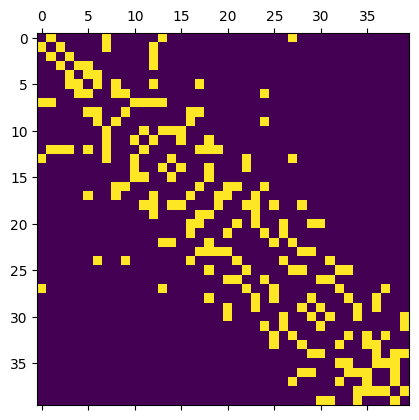

weight matrix:


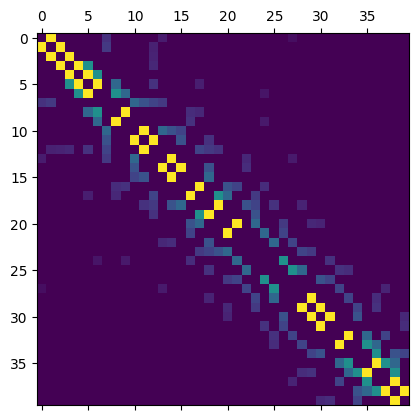

distance matrix:


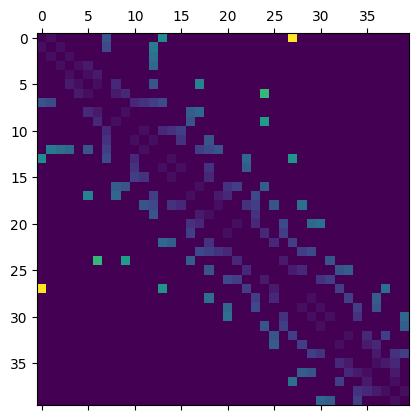

pheromone matrix:


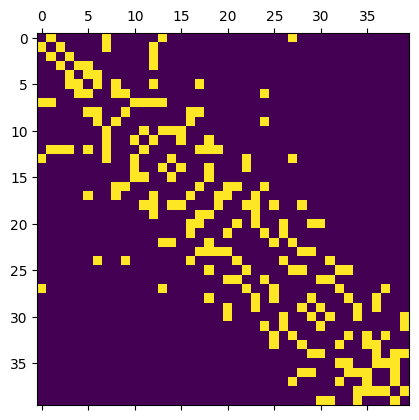

In [214]:
def generate_connection_matrix(point_coordinates, triangles):
    N = len(point_coordinates)
    vertices = np.array(range(N))

    connection_matrix = np.full((N, N), 0)
    
    for tri in triangles:
        # create all pairwise connections within the triangle
        connection_matrix[np.ix_(tri, tri)] = 1.0 # this indexing returns all pairs

    # 0 the diagonal
    np.fill_diagonal(connection_matrix, 0)

    return connection_matrix

def calc_dist(p1, p2):
    return np.linalg.norm(p1 - p2)

def generate_weight_matrix(point_coordinates, conncetion_matrix):
    pairs = np.column_stack(np.where(connection_matrix == 1))
    N = len(point_coordinates)

    weight_matrix = np.zeros((N,N))

    for p1, p2 in pairs:
        distance = calc_dist(p1,p2)
        weight_matrix[p1,p2] = 1.0 / distance

    return weight_matrix

def generate_distance_matrix(point_coordinates, connection_matrix):
    pairs = np.column_stack(np.where(connection_matrix == 1))
    N = len(point_coordinates)

    distance_matrix = np.zeros((N,N))

    for p1, p2 in pairs:
        distance_matrix[p1,p2] = calc_dist(p1,p2)

    return distance_matrix

def initialize_pheromone_matrix(connection_matrix):
    return connection_matrix.astype(float)


connection_matrix = generate_connection_matrix(points, simplices)
print("connectrion matrix:")
plt.matshow(connection_matrix)
plt.show()

weight_matrix = generate_weight_matrix(points, connection_matrix)
print("weight matrix:")
plt.matshow(weight_matrix)
plt.show()

distance_matrix = generate_distance_matrix(points, connection_matrix)
print("distance matrix:")
plt.matshow(distance_matrix)
plt.show()

pheromone_matrix = initialize_pheromone_matrix(connection_matrix)
print("pheromone matrix:")
plt.matshow(pheromone_matrix)
plt.show()


In [215]:
def plot_pheromone_paths(points, simplices, pheromone_matrix, title="Pheromone Map"):
    """
    Plots the Delaunay mesh where edge color intensity 
    corresponds to pheromone levels.
    """
    plt.figure(figsize=(8, 6.5))
    
    # 1. Create a set of unique edges from the triangles to avoid double-drawing
    edges = set()
    for tri in simplices:
        for i in range(3):
            # Sort the pair to ensure (1, 2) and (2, 1) are treated as the same edge
            edge = tuple(sorted((tri[i], tri[(i + 1) % 3])))
            edges.add(edge)
    
    # 2. Get the maximum pheromone value for normalization
    max_pheromone = np.max(pheromone_matrix)
    if max_pheromone == 0: 
        max_pheromone = 1 # Avoid division by zero
        
    # 3. Plot each edge
    for p1_idx, p2_idx in edges:
        p1 = points[p1_idx]
        p2 = points[p2_idx]
        
        # Use the pheromone value to determine color
        # We look up the value in the matrix. 
        # (Assuming the matrix is symmetric after the run_simulation update)
        val = pheromone_matrix[p1_idx, p2_idx]
        
        # Mapping the value to a color (Viridis is great for visibility)
        color = plt.cm.viridis(val / max_pheromone)
        
        # Set alpha/linewidth based on intensity so weak paths fade out
        linewidth = 1 + (4 * (val / max_pheromone))
        alpha = 0.2 + (0.8 * (val / max_pheromone))
        
        plt.plot([p1[0], p2[0]], [p1[1], p2[1]], 
                 color=color, lw=linewidth, alpha=alpha, zorder=1)

    # 4. Plot the points (nodes)
    plt.scatter(points[:, 0], points[:, 1], color='red', s=30, zorder=2, edgecolors='black')
    
    # Label indices for easier debugging/analysis
    for i, p in enumerate(points):
        plt.text(p[0] + 0.2, p[1] + 0.2, str(i), fontsize=9)

    plt.title(title)
    plt.xlabel("X Coordinate")
    plt.ylabel("Y Coordinate")
    # Create the mappable and specify the axes (ax) to steal space from
    sm = plt.cm.ScalarMappable(cmap='viridis', norm=plt.Normalize(vmin=0, vmax=max_pheromone))
    plt.colorbar(sm, ax=plt.gca(), label='Pheromone Intensity')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

# Example usage:
# plot_pheromone_paths(points, simplices, pheromone_matrix)

In [216]:
if False:
    ALPHA = 1
    BETA = 1
    Q = 1
    RO = 0.5

    def compute_next_step(vertex, connection_matrix, weight_matrix, pheromone_matrix):
        candidates = np.where(connection_matrix[vertex])[0]

        _prob = weight_matrix[vertex, candidates]**ALPHA * pheromone_matrix[vertex, candidates]**BETA # not real probability
        omega = np.sum(_prob)
        prob = _prob / omega # compute actual probabilities

        return np.random.choice(candidates, p=prob)

    def run_simulation(start_end, batch_count, connection_matrix, weight_matrix, distance_matrix, pheromone_matrix):
        """
        Every ant starts at the same vertex.
        It wanders randomly according to some probability.
        Once it reaches the end point it is killed and the process repeats.

        Pheromones are updated every batch, not every ant.
        """
        batch_size = 100
        start, end = start_end

        # for _ in range(batch_count):
        records = []
        for i in range(batch_count*batch_size):
            if (i + 1) % batch_size == 0:
                # update the pheromone matrix
                pheromone_matrix *= RO # evaporation
                for distance, p1, p2 in records:
                    # update the pheromone matrix
                    pheromone_matrix[p1,p2] += Q / distance
                records = []
                
            pos = start
            distance = 0
            while pos != end:
                # choose the next step
                next = compute_next_step(pos, connection_matrix, weight_matrix, pheromone_matrix)
                distance += distance_matrix[pos, next]
                # add twice to make sure that the pheromone matrix is updated correctly
                records.append((distance, pos, next))
                records.append((distance, next, pos))
                pos = next



    run_simulation((0,10),10, connection_matrix, weight_matrix, distance_matrix, pheromone_matrix)

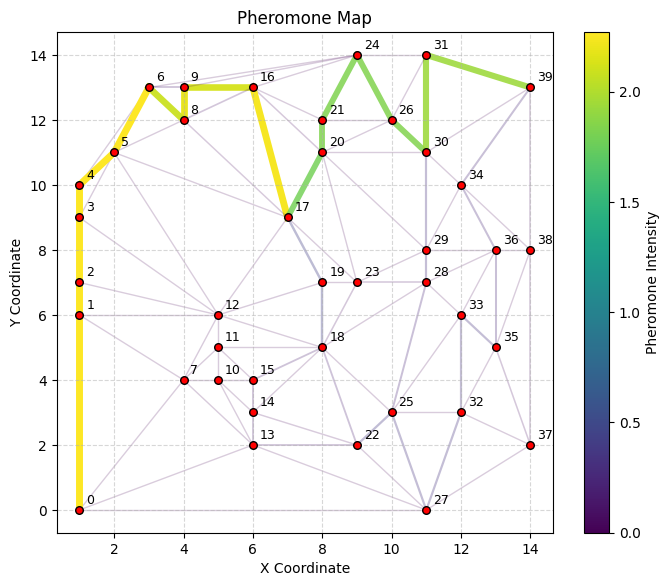

In [217]:
ALPHA = 1
BETA = 1
Q = 1
RO = 0.5
EPSILON = 0.0    # 10% chaos/exploration
 # 30% of total batch pheromones are reassigned to the global best path

def compute_next_step(vertex, heuristic_matrix, pheromone_matrix, adjacency_list, epsilon=EPSILON):
    candidates = adjacency_list[vertex]
    num_candidates = len(candidates)
    
    # Standard ACO weights
    _prob = (heuristic_matrix[vertex, candidates]) * (pheromone_matrix[vertex, candidates] ** BETA)
    sum_prob = np.sum(_prob)
    
    if sum_prob == 0:
        return np.random.choice(candidates)
    
    p_aco = _prob / sum_prob
    p_chaos = np.full(num_candidates, 1.0 / num_candidates)
    
    # Blend ACO and Chaos
    final_probs = (1 - epsilon) * p_aco + (epsilon) * p_chaos
    
    cum_prob = np.cumsum(final_probs)
    return candidates[np.searchsorted(cum_prob, np.random.rand())]

def run_simulation(start_end, batch_count, connection_matrix, weight_matrix, distance_matrix, pheromone_matrix):
    ELITE_FACTOR = 0.0
    batch_size = 50
    start, end = start_end
    
    heuristic_matrix = weight_matrix ** ALPHA
    num_vertices = len(connection_matrix)
    base_adjacency_list = [np.where(connection_matrix[i])[0] for i in range(num_vertices)]

    # Tracking the Global Best
    global_best_path = None
    global_best_dist = float('inf')

    for batch in range(batch_count):
        batch_records = []
        total_batch_deposit = 0
        ELITE_FACTOR *= 1.2
        
        for ant in range(batch_size):
            pos = start
            tour_distance = 0
            path = []
            visited = {start}
            dead_end = False
            
            while pos != end:
                valid_candidates = [c for c in base_adjacency_list[pos] if c not in visited]
                if not valid_candidates:
                    dead_end = True
                    break
                    
                temp_adjacency = list(base_adjacency_list) 
                temp_adjacency[pos] = np.array(valid_candidates)
                
                next_pos = compute_next_step(pos, heuristic_matrix, pheromone_matrix, temp_adjacency)
                
                tour_distance += distance_matrix[pos, next_pos]
                path.append((pos, next_pos))
                visited.add(next_pos)
                pos = next_pos
                
            if not dead_end:
                batch_records.append((tour_distance, path))
                # Update Global Best if this ant found a shorter route
                if tour_distance < global_best_dist:
                    global_best_dist = tour_distance
                    global_best_path = path

        # 1. Evaporation
        pheromone_matrix *= RO
        
        # 2. Regular Deposit + Calculate sum for Elite bonus
        current_batch_sum = 0
        for tour_distance, path in batch_records:
            deposit_amount = Q / tour_distance
            current_batch_sum += deposit_amount
            for p1, p2 in path:
                pheromone_matrix[p1, p2] += deposit_amount
                pheromone_matrix[p2, p1] += deposit_amount
        
        # 3. Elitist Enforcement
        # We take ELITE_FACTOR of the total pheromones deposited this batch 
        # and re-apply them specifically to the best path ever found.
        if global_best_path:
            elite_deposit = current_batch_sum * ELITE_FACTOR
            for p1, p2 in global_best_path:
                pheromone_matrix[p1, p2] += elite_deposit
                pheromone_matrix[p2, p1] += elite_deposit
    
    return pheromone_matrix

# To run:
pheromone_matrix = run_simulation((0,39), 23, connection_matrix, weight_matrix, distance_matrix, pheromone_matrix)
plot_pheromone_paths(points, simplices, pheromone_matrix)